# 02. TWFE推定

Y_iy = beta log(MW_iy) + alpha_i + gamma_y + epsilon_iy

最低賃金年度ベースの年次パネルでのTwo-Way Fixed Effects推定。
最低賃金の改定月（主に10月）と月次季節性の扱いを避け、dcDH推定と同じ年次サンプルに揃える。


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')
import japanize_matplotlib
from pathlib import Path
from linearmodels.panel import PanelOLS

OUT = Path('../output')
OUT.mkdir(parents=True, exist_ok=True)
(OUT / 'figures').mkdir(exist_ok=True)

annual_raw = pd.read_csv('../data/annual_panel.csv')

# 完全年のみを使用する。
# 2018・2019・2025はMW年度内の観測月数が不足しており、2019はMW改定月を跨ぐ欠測もある。
clean_years = [2013, 2014, 2015, 2016, 2017, 2020, 2021, 2022, 2023, 2024]
df = annual_raw[annual_raw['mw_year'].isin(clean_years)].copy()
df = df.set_index(['pref_code', 'mw_year'])

print(f'Raw annual panel: {annual_raw.shape}')
print(f'Estimation panel: {df.shape}')
print(f'Years: {sorted(df.index.get_level_values("mw_year").unique())}')
print(f'Prefectures: {df.index.get_level_values("pref_code").nunique()}')


Raw annual panel: (658, 19)
Estimation panel: (470, 17)
Years: [2013, 2014, 2015, 2016, 2017, 2020, 2021, 2022, 2023, 2024]
Prefectures: 47


## 1. ベースライン TWFE

In [2]:
outcomes = {
    'log_wage_total': 'log(現金給与総額)',
    'log_wage_scheduled': 'log(所定内給与)',
    'hours_total': '総実労働時間',
    'log_hours_total': 'log(総実労働時間)',
    'hours_scheduled': '所定内労働時間',
    'hours_overtime': '所定外労働時間',
    'log_workers': 'log(常用労働者数)',
}

results = []
for yvar, label in outcomes.items():
    mod = PanelOLS(df[yvar], df[['log_mw']],
                   entity_effects=True, time_effects=True)
    res = mod.fit(cov_type='clustered', cluster_entity=True)
    results.append({
        'outcome': label,
        'beta': res.params['log_mw'],
        'se': res.std_errors['log_mw'],
        't': res.tstats['log_mw'],
        'p': res.pvalues['log_mw'],
        'N': res.nobs,
        'R2_within': res.rsquared_within,
        'sample': 'annual_clean_2013_2017_2020_2024',
    })

tab = pd.DataFrame(results)
tab['sig'] = tab['p'].apply(lambda p: '***' if p < 0.01 else '**' if p < 0.05 else '*' if p < 0.1 else '')
tab['beta_se'] = tab.apply(lambda r: f"{r['beta']:.4f} ({r['se']:.4f}){r['sig']}", axis=1)

print('=== 年次TWFE ベースライン: Y_iy = beta log(MW_iy) + alpha_i + gamma_y + epsilon_iy ===')
print('SE: 都道府県クラスター')
print('Sample: complete MW-years only (2013-2017, 2020-2024)')
print()
print(tab[['outcome', 'beta_se', 'N', 'R2_within']].to_string(index=False))


=== 年次TWFE ベースライン: Y_iy = beta log(MW_iy) + alpha_i + gamma_y + epsilon_iy ===
SE: 都道府県クラスター
Sample: complete MW-years only (2013-2017, 2020-2024)

    outcome               beta_se   N  R2_within
log(現金給与総額)      -0.1038 (0.2316) 470  -0.620810
 log(所定内給与)      -0.1162 (0.2095) 470  -0.876078
     総実労働時間  -44.5460 (18.4658)** 470   0.813440
log(総実労働時間)     -0.2315 (0.1383)* 470   0.798032
    所定内労働時間 -42.3058 (15.4048)*** 470   0.793636
    所定外労働時間      -2.2402 (5.5919) 470   0.326417
log(常用労働者数)      -0.5428 (0.4984) 470  -4.667549


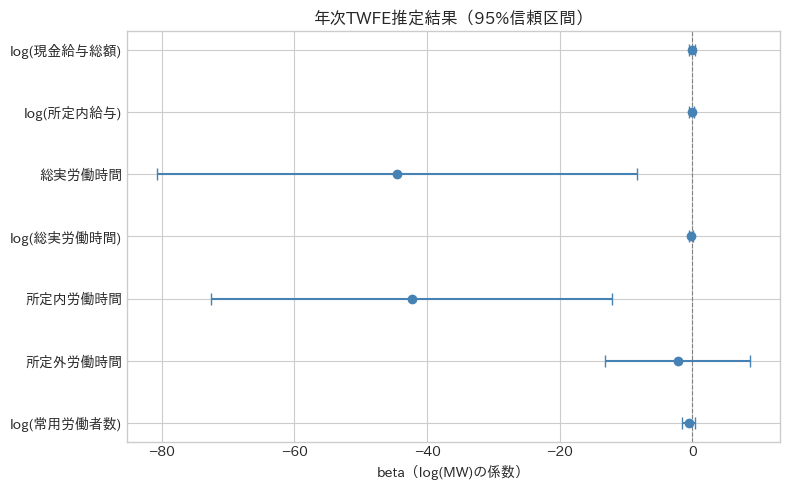

In [3]:
# 係数プロット
fig, ax = plt.subplots(figsize=(8, 5))
tab_plot = pd.DataFrame(results)
y_pos = range(len(tab_plot))

ax.errorbar(tab_plot['beta'], y_pos,
            xerr=1.96 * tab_plot['se'],
            fmt='o', color='steelblue', capsize=4, markersize=6)
ax.axvline(0, color='gray', linestyle='--', linewidth=0.8)
ax.set_yticks(list(y_pos))
ax.set_yticklabels([outcomes[k] for k in outcomes.keys()])
ax.set_xlabel('beta（log(MW)の係数）')
ax.set_title('年次TWFE推定結果（95%信頼区間）')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(OUT / 'figures' / '02_twfe_coef_plot.png', dpi=150, bbox_inches='tight')
plt.show()


## 2. 主要アウトカムの詳細出力

In [4]:
# 所定内給与と総実労働時間の詳細
for yvar, label in [('log_wage_scheduled', 'log(所定内給与)'),
                     ('log_hours_total', 'log(総実労働時間)')]:
    mod = PanelOLS(df[yvar], df[['log_mw']],
                   entity_effects=True, time_effects=True)
    res = mod.fit(cov_type='clustered', cluster_entity=True)
    print(f'\n{"="*60}')
    print(f'アウトカム: {label}')
    print(f'{"="*60}')
    print(res.summary)


アウトカム: log(所定内給与)
                          PanelOLS Estimation Summary                           
Dep. Variable:     log_wage_scheduled   R-squared:                        0.0029
Estimator:                   PanelOLS   R-squared (Between):             -0.1304
No. Observations:                 470   R-squared (Within):              -0.8761
Date:                Mon, Oct 05 2026   R-squared (Overall):             -0.1304
Time:                        16:28:00   Log-likelihood                    1299.3
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      1.1946
Entities:                          47   P-value                           0.2750
Avg Obs:                      10.0000   Distribution:                   F(1,413)
Min Obs:                      10.0000                                           
Max Obs:                      10.0000   F-statistic (robust):             0.3077
         

## 3. 頑健性チェック

In [5]:
# 頑健性チェック: COVID期除外、前半/後半サンプル
df_orig = df.copy()
df_orig['mw_year'] = df_orig.index.get_level_values('mw_year')

samples = {
    'ベースライン': df_orig,
    'コロナ除外(2020-21)': df_orig[~df_orig['mw_year'].isin([2020, 2021])],
    '2013-2017のみ': df_orig[df_orig['mw_year'] <= 2017],
    '2020-2024のみ': df_orig[df_orig['mw_year'] >= 2020],
}

key_outcomes = ['log_wage_scheduled', 'log_hours_total', 'hours_overtime']
key_labels = ['log(所定内給与)', 'log(総実労働時間)', '所定外労働時間']

robust_results = []
for sname, sdf in samples.items():
    for yvar, label in zip(key_outcomes, key_labels):
        try:
            mod = PanelOLS(sdf[yvar], sdf[['log_mw']],
                           entity_effects=True, time_effects=True)
            res = mod.fit(cov_type='clustered', cluster_entity=True)
            robust_results.append({
                'sample': sname,
                'outcome': label,
                'beta': res.params['log_mw'],
                'se': res.std_errors['log_mw'],
                'p': res.pvalues['log_mw'],
                'N': res.nobs,
            })
        except Exception as e:
            robust_results.append({
                'sample': sname, 'outcome': label,
                'beta': np.nan, 'se': np.nan, 'p': np.nan, 'N': 0,
                'error': str(e),
            })

rtab = pd.DataFrame(robust_results)
rtab['sig'] = rtab['p'].apply(lambda p: '***' if p < 0.01 else '**' if p < 0.05 else '*' if p < 0.1 else '' if not np.isnan(p) else '')
rtab['coef'] = rtab.apply(lambda r: f"{r['beta']:.4f} ({r['se']:.4f}){r['sig']}" if not np.isnan(r['beta']) else 'N/A', axis=1)

pivot = rtab.pivot(index='sample', columns='outcome', values='coef')
pivot = pivot.reindex(['ベースライン', 'コロナ除外(2020-21)', '2013-2017のみ', '2020-2024のみ'])

print('=== 年次TWFE 頑健性チェック ===')
print(pivot.to_string())


=== 年次TWFE 頑健性チェック ===
outcome                 log(所定内給与)        log(総実労働時間)             所定外労働時間
sample                                                                   
ベースライン            -0.1162 (0.2095)  -0.2315 (0.1383)*    -2.2402 (5.5919)
コロナ除外(2020-21)    -0.1190 (0.2139)  -0.2385 (0.1395)*    -2.1459 (5.4667)
2013-2017のみ     -0.8438 (0.3845)**    0.0534 (0.2304)   20.2855 (16.9619)
2020-2024のみ        0.0954 (0.2372)   -0.3374 (0.2359)  -14.3842 (7.3635)*


In [6]:
# 都道府県固有線形トレンド
df_trend = df_orig.copy()

year_vals = sorted(df_trend.index.get_level_values('mw_year').unique())
year_to_t = {yr: i for i, yr in enumerate(year_vals)}
df_trend['t'] = df_trend.index.get_level_values('mw_year').map(year_to_t)

pref_codes = df_trend.index.get_level_values('pref_code')
for p in sorted(pref_codes.unique())[1:]:
    df_trend[f'pref{p}_t'] = (pref_codes == p).astype(int) * df_trend['t']

trend_cols = [c for c in df_trend.columns if c.startswith('pref') and c.endswith('_t')]

print('=== 都道府県固有線形トレンド追加 ===')
trend_results = []
for yvar, label in zip(key_outcomes, key_labels):
    mod0 = PanelOLS(df_trend[yvar], df_trend[['log_mw']],
                    entity_effects=True, time_effects=True)
    res0 = mod0.fit(cov_type='clustered', cluster_entity=True)
    
    try:
        mod1 = PanelOLS(df_trend[yvar], df_trend[['log_mw'] + trend_cols],
                        entity_effects=True, time_effects=True, drop_absorbed=True)
        res1 = mod1.fit(cov_type='clustered', cluster_entity=True)
        with_trend = f"{res1.params['log_mw']:.4f} ({res1.std_errors['log_mw']:.4f})"
    except Exception as e:
        with_trend = f'N/A: {type(e).__name__}'

    trend_results.append({
        'outcome': label,
        'baseline': f"{res0.params['log_mw']:.4f} ({res0.std_errors['log_mw']:.4f})",
        'with_trend': with_trend,
    })

ttab = pd.DataFrame(trend_results)
print(ttab.to_string(index=False))


=== 都道府県固有線形トレンド追加 ===


    outcome         baseline         with_trend
 log(所定内給与) -0.1162 (0.2095)    0.0485 (0.3537)
log(総実労働時間) -0.2315 (0.1383)   -0.2460 (0.2153)
    所定外労働時間 -2.2402 (5.5919) -20.9457 (10.4735)


## 4. サンプル定義の確認

In [7]:
# MW年度ごとの観測月数を確認
year_info = (
    annual_raw
    .groupby('mw_year')
    .agg(n_pref=('pref_code', 'nunique'), n_months=('n_months', 'first'))
    .reset_index()
)
year_info['used_in_baseline'] = year_info['mw_year'].isin(clean_years)

print(year_info.to_string(index=False))
print()
print('Baseline uses complete MW-years only:')
print(clean_years)


 mw_year  n_pref  n_months  used_in_baseline
    2012      47         9             False
    2013      47        12              True
    2014      47        12              True
    2015      47        12              True
    2016      47        12              True
    2017      47        12              True
    2018      47         3             False
    2019      47         9             False
    2020      47        12              True
    2021      47        12              True
    2022      47        12              True
    2023      47        12              True
    2024      47        12              True
    2025      47         6             False

Baseline uses complete MW-years only:
[2013, 2014, 2015, 2016, 2017, 2020, 2021, 2022, 2023, 2024]


## 5. 結果保存

In [8]:
# ベースライン結果をCSVで保存
save_tab = pd.DataFrame(results)
save_tab.to_csv(OUT / 'twfe_baseline.csv', index=False)

# 頑健性結果も保存
rtab.to_csv(OUT / 'twfe_robustness.csv', index=False)

print('保存完了:')
print('  output/twfe_baseline.csv')
print('  output/twfe_robustness.csv')
print('  output/figures/02_twfe_coef_plot.png')


保存完了:
  output/twfe_baseline.csv
  output/twfe_robustness.csv
  output/figures/02_twfe_coef_plot.png


## 6. 解釈メモ

### TWFEが推定しているもの

このTWFEの beta は log(MW) の within 変動（都道府県FE・年FE除去後）に対するアウトカムの応答。

月次ではなく最低賃金年度ベースの年次パネルを使う理由:

1. 最低賃金は主に10月改定であり、月次では処置開始月・ラグ・季節性の扱いが論点化しやすい。
2. 本研究の焦点は短期月次反応ではなく、連続処置DiDにおける推定量・estimandの比較である。
3. dcDH推定も年次パネルで実装しているため、TWFEとの比較対象を揃えられる。

**問題点**（Callaway et al. 2024）:
1. **estimand**: beta は dose-response tau(d) の加重平均だが、関心のあるdose-responseとは一致しない場合がある。
2. **heterogeneity**: tau(d) が d や都道府県に依存する場合、TWFEの係数は解釈しづらい。
3. **finite sample**: 47都道府県かつ完全年10年なので、推定量の有限標本挙動も重要。

→ dcDH推定・Monte Carloと比較し、TWFEの推定結果が推定誤差なのかestimand問題なのかを切り分ける。
